# Training An AI to play Chrome Dino Game with Reinforcement Learning (RL)

## Install Dependecies

In [1]:
!pip install -q gymnasium stable-baselines3[extra] pygame imageio imageio-ffmpeg matplotlib opencv-python

## Build the Custom Chrome Dino Gymnasium Environment (With Visual Renderer)
Environment with 2-Obstacle Lookahead & Ghost/Telemetry Renderer

In [2]:
import os
os.environ["SDL_VIDEODRIVER"] = "dummy"

import gymnasium as gym
from gymnasium import spaces
import numpy as np
import pygame
import torch

# =====================================================================
# 1. AUTHENTIC PIXEL-ART SPRITE BITMAPS (Modeled after chrome://dino)
# =====================================================================
DINO_STAND_1 = [
    "          XXXXXXXXX ",
    "         XX.XXXXXXX ",
    "         XXXXXXXXXX ",
    "         XXXXXXXXXX ",
    "         XXXXX      ",
    "         XXXXXXXXX  ",
    "X       XXXXXX      ",
    "XX     XXXXXXX      ",
    "XXX   XXXXXXXXXX    ",
    "XXXX XXXXXXXXX  X   ",
    "XXXXXXXXXXXXXX      ",
    "XXXXXXXXXXXXXX      ",
    " XXXXXXXXXXXX       ",
    "  XXXXXXXXXX        ",
    "   XXXXXXXX         ",
    "    XXXXXX          ",
    "    XXX  XX         ",
    "    XX    X         ",
    "    X     XX        ",
    "    XX              "
]

DINO_STAND_2 = [
    "          XXXXXXXXX ",
    "         XX.XXXXXXX ",
    "         XXXXXXXXXX ",
    "         XXXXXXXXXX ",
    "         XXXXX      ",
    "         XXXXXXXXX  ",
    "X       XXXXXX      ",
    "XX     XXXXXXX      ",
    "XXX   XXXXXXXXXX    ",
    "XXXX XXXXXXXXX  X   ",
    "XXXXXXXXXXXXXX      ",
    "XXXXXXXXXXXXXX      ",
    " XXXXXXXXXXXX       ",
    "  XXXXXXXXXX        ",
    "   XXXXXXXX         ",
    "    XXXXXX          ",
    "    XX  XXX         ",
    "    X    XX         ",
    "    XX    X         ",
    "          XX        "
]

DINO_DUCK_1 = [
    "                XXXXXXXXX ",
    "               XX.XXXXXXX ",
    "X              XXXXXXXXXX ",
    "XX     XXXXXXXXXXXXXXXXXX ",
    "XXX  XXXXXXXXXXXXXXX      ",
    "XXXXXXXXXXXXXXXXXXXXXXX   ",
    " XXXXXXXXXXXXXXXXXX  X    ",
    "  XXXXXXXXXXXXXXX         ",
    "    XXXXXXXXXXXX          ",
    "      XXX   XX            ",
    "      XX     XX           ",
    "      XX                  "
]

DINO_DUCK_2 = [
    "                XXXXXXXXX ",
    "               XX.XXXXXXX ",
    "X              XXXXXXXXXX ",
    "XX     XXXXXXXXXXXXXXXXXX ",
    "XXX  XXXXXXXXXXXXXXX      ",
    "XXXXXXXXXXXXXXXXXXXXXXX   ",
    " XXXXXXXXXXXXXXXXXX  X    ",
    "  XXXXXXXXXXXXXXX         ",
    "    XXXXXXXXXXXX          ",
    "      XX    XXX           ",
    "       XX   XX            ",
    "            XX            "
]

CACTUS_SINGLE = [
    "    XX      ",
    "   XXXX     ",
    "   XXXX     ",
    "   XXXX  XX ",
    "XX XXXX XXXX",
    "XXXXXXX XXXX",
    "XXXXXXX XXXX",
    "XXXXXXX XXXX",
    " XXXXXXXXXX ",
    "  XXXXXXXX  ",
    "   XXXX     ",
    "   XXXX     ",
    "   XXXX     ",
    "   XXXX     ",
    "   XXXX     ",
    "   XXXX     "
]

BIRD_WING_UP = [
    "      XX            ",
    "     XXX            ",
    "    XXXX   XX       ",
    "   XXXXX  XXXX      ",
    "  XXXXXX XXXXXX     ",
    " XXXXXXXXXXXXXXX    ",
    "XXXXXXXXXXXXXXXXX   ",
    "      XXXXXXXXXXXX  ",
    "        XXXXXXXXXXXX",
    "          XXXXXXX   ",
    "                    ",
    "                    "
]

BIRD_WING_DOWN = [
    "                    ",
    "      XX            ",
    "     XXX            ",
    "    XXXX            ",
    "   XXXXXX           ",
    " XXXXXXXXXXXXXXX    ",
    "XXXXXXXXXXXXXXXXXX  ",
    "      XXXXXXXXXXXXXX",
    "       XXXXXXX   XX ",
    "       XXXXX        ",
    "        XXX         ",
    "         X          "
]

def bitmap_to_surface(bitmap, scale=2, color=(172, 172, 172), alpha=255):
    """Converts a string pixel-art matrix into a crisp scaled Pygame Surface."""
    h, w = len(bitmap), len(bitmap[0])
    surf = pygame.Surface((w * scale, h * scale), pygame.SRCALPHA)
    for r, row in enumerate(bitmap):
        for c, ch in enumerate(row):
            if ch == "X":
                pygame.draw.rect(surf, (*color, alpha), (c * scale, r * scale, scale, scale))
            elif ch == ".":
                pygame.draw.rect(surf, (32, 33, 36, alpha), (c * scale, r * scale, scale, scale))
    return surf


class SuperDinoEnv(gym.Env):
    metadata = {"render_modes": ["rgb_array"], "render_fps": 30}

    def __init__(self, render_mode="rgb_array", max_score=5000):
        super().__init__()
        self.render_mode = render_mode
        # 16:9 Widescreen Dimensions (704x400 is divisible by 16 for FFmpeg)
        self.width, self.height = 704, 400
        self.ground_y = 300
        self.max_score = max_score

        pygame.init()
        self.surface = pygame.Surface((self.width, self.height), pygame.SRCALPHA)
        self.font = pygame.font.SysFont("monospace", 16, bold=True)
        self.small_font = pygame.font.SysFont("monospace", 12, bold=True)

        # Pre-build authentic pixel-art sprites
        self.sprites = {
            "run1": bitmap_to_surface(DINO_STAND_1, scale=2),
            "run2": bitmap_to_surface(DINO_STAND_2, scale=2),
            "duck1": bitmap_to_surface(DINO_DUCK_1, scale=2),
            "duck2": bitmap_to_surface(DINO_DUCK_2, scale=2),
            "bird1": bitmap_to_surface(BIRD_WING_UP, scale=2, color=(185, 185, 185)),
            "bird2": bitmap_to_surface(BIRD_WING_DOWN, scale=2, color=(185, 185, 185)),
            "cactus_s": bitmap_to_surface(CACTUS_SINGLE, scale=2, color=(172, 172, 172)),
            "cactus_l": bitmap_to_surface(CACTUS_SINGLE, scale=3, color=(172, 172, 172)),
        }

        # Action Space: 0 = Run, 1 = Jump, 2 = Duck / Fast-Fall
        self.action_space = spaces.Discrete(3)

        # 12-Feature Engineered State Space with Time-To-Impact (TTI):
        # [dx1_norm, tti1_norm, w1_norm, is_cactus1, is_low_bird1, is_high_bird1,
        #  dx2_norm, tti2_norm, is_low_bird2, dino_y_norm, dino_vel_y_norm, speed_norm]
        self.observation_space = spaces.Box(
            low=-2.0, high=3.0, shape=(12,), dtype=np.float32
        )
        self.reset()

    def reset(self, seed=None, options=None):
        super().reset(seed=seed)
        self.dino_x = 65
        self.dino_y = float(self.ground_y - 40)
        self.dino_vel_y = 0.0
        self.is_jumping = False
        self.is_ducking = False

        self.gravity = 1.25
        self.jump_strength = -15.5
        self.game_speed = 7.0
        self.score = 0
        self.obstacles_cleared = 0
        self.step_count = 0
        self.crashed = False

        self.obstacles = []
        # Spawn first obstacle close (x=420) so agent immediately practices jumping!
        self._spawn_obstacle(custom_x=420)
        self._spawn_obstacle()
        self._spawn_obstacle()
        return self._get_obs(), {"score": self.score, "cleared": 0}

    def _spawn_obstacle(self, custom_x=None):
        if custom_x is not None:
            spawn_x = float(custom_x)
        else:
            last_x = max([o['x'] + o['w'] for o in self.obstacles], default=self.width)
            min_gap = int(210 + self.game_speed * 14)
            max_gap = min_gap + int(160 + self.game_speed * 6)
            spawn_x = float(last_x + self.np_random.integers(min_gap, max_gap))

        # Introduce flying Pterodactyls once score >= 60 so agent masters birds early
        probs = [0.30, 0.30, 0.25, 0.15] if self.score >= 60 else [0.5, 0.5, 0.0, 0.0]
        obs_type = self.np_random.choice(["small_cactus", "large_cactus", "bird_low", "bird_high"], p=probs)

        if obs_type == "small_cactus":
            clusters = int(self.np_random.choice([1, 2, 3], p=[0.45, 0.35, 0.20]))
            w, h = 24 * clusters, 32
            y = self.ground_y - h
        elif obs_type == "large_cactus":
            clusters = int(self.np_random.choice([1, 2], p=[0.55, 0.45]))
            w, h = 36 * clusters, 48
            y = self.ground_y - h
        elif obs_type == "bird_low":
            # Bottom of bird is at ground_y - 24 -> hits standing dino (40px), misses ducking dino (24px)!
            w, h, clusters = 40, 24, 1
            y = self.ground_y - 48
        else:  # bird_high
            # Bottom of bird is at ground_y - 52 -> safe to run under, fatal if jumped into!
            w, h, clusters = 40, 24, 1
            y = self.ground_y - 76

        self.obstacles.append({
            'x': spawn_x, 'y': float(y), 'w': w, 'h': h,
            'type': obs_type, 'clusters': clusters
        })

    def step(self, action):
        self.step_count += 1
        self.is_ducking = False

        upcoming = [o for o in self.obstacles if o['x'] + o['w'] >= self.dino_x]
        next_obs = upcoming[0] if upcoming else self.obstacles[0]
        dx = next_obs['x'] - (self.dino_x + 36)

        reward = 0.1  # Base survival reward

        # 1. Handle Actions & Penalize Pointless Jumping
        if action == 1 and not self.is_jumping:
            self.dino_vel_y = self.jump_strength
            self.is_jumping = True
            # Penalize jumping when no obstacle is within jump range or when a high bird is approaching
            if dx > 190 or next_obs['type'] == "bird_high":
                reward -= 0.6
            else:
                reward -= 0.02
        elif action == 2:
            if self.is_jumping:
                self.dino_vel_y += 3.5  # Fast-fall
            else:
                self.is_ducking = True
                # Reward ducking when a low bird is close; slightly penalize ducking with nothing near
                if next_obs['type'] == "bird_low" and dx < 140:
                    reward += 0.25
                elif dx > 190:
                    reward -= 0.15

        # 2. Update Dino Physics
        dino_h = 24 if self.is_ducking else 40
        dino_w = 50 if self.is_ducking else 40

        if self.is_jumping:
            self.dino_y += self.dino_vel_y
            self.dino_vel_y += self.gravity
            if self.dino_y >= self.ground_y - dino_h:
                self.dino_y = float(self.ground_y - dino_h)
                self.dino_vel_y = 0.0
                self.is_jumping = False
        else:
            self.dino_y = float(self.ground_y - dino_h)

        # 3. Move Obstacles & Check Clearance
        for obs in self.obstacles:
            obs['x'] -= self.game_speed

        if self.obstacles and self.obstacles[0]['x'] + self.obstacles[0]['w'] < self.dino_x:
            self.obstacles.pop(0)
            self.obstacles_cleared += 1
            reward += 4.0  # Big milestone reward for clearing an obstacle!

        while len(self.obstacles) < 4:
            self._spawn_obstacle()

        # 4. Tight Hitbox Collision Detection
        dino_rect = pygame.Rect(self.dino_x + 6, int(self.dino_y) + 4, dino_w - 14, dino_h - 8)
        for obs in self.obstacles:
            obs_rect = pygame.Rect(int(obs['x']) + 4, int(obs['y']) + 3, obs['w'] - 8, obs['h'] - 6)
            if dino_rect.colliderect(obs_rect):
                self.crashed = True
                reward = -15.0
                break

        self.score = self.step_count // 3
        self.game_speed = min(14.5, 7.0 + (self.score / 220.0))
        truncated = self.score >= self.max_score

        return self._get_obs(), reward, self.crashed, truncated, {
            "score": self.score,
            "cleared": self.obstacles_cleared
        }

    def _get_obs(self):
        upcoming = [o for o in self.obstacles if o['x'] + o['w'] >= self.dino_x]
        obs1 = upcoming[0] if len(upcoming) > 0 else {'x': 700.0, 'w': 24, 'type': 'small_cactus'}
        obs2 = upcoming[1] if len(upcoming) > 1 else {'x': 1100.0, 'w': 24, 'type': 'small_cactus'}

        dx1 = obs1['x'] - (self.dino_x + 36)
        dx2 = obs2['x'] - (self.dino_x + 36)

        # Time-To-Impact (in frames, normalized by 25-frame jump duration)
        tti1 = (dx1 / self.game_speed) / 25.0
        tti2 = (dx2 / self.game_speed) / 25.0

        return np.array([
            dx1 / 400.0,
            tti1,
            obs1['w'] / 80.0,
            1.0 if "cactus" in obs1['type'] else 0.0,
            1.0 if obs1['type'] == "bird_low" else 0.0,
            1.0 if obs1['type'] == "bird_high" else 0.0,
            dx2 / 400.0,
            tti2,
            1.0 if obs2['type'] == "bird_low" else 0.0,
            (self.ground_y - self.dino_y - 40) / 100.0,
            self.dino_vel_y / 16.0,
            (self.game_speed - 7.0) / 8.0
        ], dtype=np.float32)

    def draw_world_base(self, surf):
        """Draws the authentic Chrome Dino dark-mode sky, moon, stars, clouds, ground, and obstacles."""
        surf.fill((32, 33, 36))

        # Crescent Moon & Stars positioned for 704x400 widescreen sky
        pygame.draw.circle(surf, (70, 72, 76), (110, 120), 22)
        pygame.draw.circle(surf, (32, 33, 36), (102, 116), 19)
        for sx, sy in [(210, 95), (310, 75), (490, 130), (620, 85), (390, 155)]:
            px = (sx - self.step_count // 4) % self.width
            pygame.draw.line(surf, (90, 92, 96), (px - 3, sy), (px + 3, sy), 1)
            pygame.draw.line(surf, (90, 92, 96), (px, sy - 3), (px, sy + 3), 1)

        # Horizon Line & Scrolling Pebbles
        pygame.draw.line(surf, (165, 165, 165), (0, self.ground_y), (self.width, self.ground_y), 2)
        for i in range(0, self.width, 35):
            px = (i - int(self.step_count * self.game_speed)) % self.width
            w_peb = 6 if (i % 70 == 0) else 3
            y_peb = self.ground_y + (5 if i % 2 == 0 else 9)
            pygame.draw.line(surf, (130, 130, 130), (px, y_peb), (px + w_peb, y_peb), 2)

        # Draw Pixel-Art Obstacles (Cacti clusters & Flapping Pterodactyls)
        flap_frame = "bird1" if (self.step_count // 6) % 2 == 0 else "bird2"
        for obs in self.obstacles:
            if -80 < obs['x'] < self.width + 20:
                if obs['type'] == "small_cactus":
                    for c in range(obs['clusters']):
                        surf.blit(self.sprites["cactus_s"], (int(obs['x']) + c * 24, int(obs['y'])))
                elif obs['type'] == "large_cactus":
                    for c in range(obs['clusters']):
                        surf.blit(self.sprites["cactus_l"], (int(obs['x']) + c * 36, int(obs['y'])))
                else:
                    surf.blit(self.sprites[flap_frame], (int(obs['x']), int(obs['y'])))

    def get_dino_sprite(self, color=(172, 172, 172), alpha=255):
        leg_idx = (self.step_count // 3) % 2
        if self.is_ducking:
            bmp = DINO_DUCK_1 if leg_idx == 0 else DINO_DUCK_2
        elif self.is_jumping:
            bmp = DINO_STAND_1
        else:
            bmp = DINO_STAND_1 if leg_idx == 0 else DINO_STAND_2
        return bitmap_to_surface(bmp, scale=2, color=color, alpha=alpha)

## Train the AI & Save Evolution Checkpoints

In [3]:
import os
import shutil
from stable_baselines3 import PPO
from stable_baselines3.common.env_util import make_vec_env
from stable_baselines3.common.callbacks import BaseCallback

# Clean old logs and checkpoints so curves and models are fresh
shutil.rmtree("dino_logs", ignore_errors=True)
os.makedirs("dino_logs", exist_ok=True)
os.makedirs("dino_super_checkpoints", exist_ok=True)

class EvolutionCheckpointCallback(BaseCallback):
    """Saves exact generational snapshots during a single continuous training run."""
    def __init__(self, milestones):
        super().__init__()
        self.milestones = dict(milestones)
        self.saved = set()

    def _on_step(self) -> bool:
        for step_target, label in self.milestones.items():
            if self.num_timesteps >= step_target and label not in self.saved:
                path = f"dino_super_checkpoints/dino_{label}"
                self.model.save(path)
                self.saved.add(label)
                print(f"🏆 Milestone Reached ({self.num_timesteps:,} steps) -> Saved: {path}")
        return True

# 16 Parallel Environments for fast, high-throughput rollouts
vec_env = make_vec_env(
    lambda: SuperDinoEnv(max_score=5000),
    n_envs=16,
    seed=42,
    monitor_dir="dino_logs"
)

def lr_schedule(progress_remaining: float) -> float:
    return 1e-5 + progress_remaining * (3e-4 - 1e-5)

policy_kwargs = dict(net_arch=dict(pi=[256, 256], vf=[256, 256]))

model = PPO(
    "MlpPolicy",
    vec_env,
    policy_kwargs=policy_kwargs,
    learning_rate=lr_schedule,
    n_steps=512,           # 512 * 16 envs = 8,192 steps per rollout update
    batch_size=512,
    n_epochs=10,
    gamma=0.99,
    gae_lambda=0.95,
    ent_coef=0.003,
    device="cpu",          # Optimal for fast 12-D vector MLP rollouts in SB3
    verbose=1
)

# Save Untrained Gen 0 before training starts
model.save("dino_super_checkpoints/dino_0k_untrained")
print("✅ Saved: dino_super_checkpoints/dino_0k_untrained")

milestones = [
    (200_000, "200k_beginner"),
    (400_000, "400k_intermediate"),
    (600_000, "600k_advanced"),
    (1_000_000, "1M_superhuman")
]

callback = EvolutionCheckpointCallback(milestones)
model.learn(total_timesteps=1_000_000, callback=callback)
model.save("dino_super_checkpoints/dino_1M_superhuman")
print("🎉 1,000,000 Steps Complete! Superhuman Model Ready.")

Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the authors of your software and request that they upgrade.
See the migration guide at https://gymnasium.farama.org/introduction/migration_guide/ for additional information.
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Using cpu device
✅ Saved: dino_super_checkpoints/dino_0k_untrained


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


---------------------------------
| rollout/           |          |
|    ep_len_mean     | 62.8     |
|    ep_rew_mean     | -9.83    |
| time/              |          |
|    fps             | 9103     |
|    iterations      | 1        |
|    time_elapsed    | 0        |
|    total_timesteps | 8192     |
---------------------------------
-----------------------------------------
| rollout/                |             |
|    ep_len_mean          | 62.9        |
|    ep_rew_mean          | -9.45       |
| time/                   |             |
|    fps                  | 5756        |
|    iterations           | 2           |
|    time_elapsed         | 2           |
|    total_timesteps      | 16384       |
| train/                  |             |
|    approx_kl            | 0.009255042 |
|    clip_fraction        | 0.0499      |
|    clip_range           | 0.2         |
|    entropy_loss         | -1.09       |
|    explained_variance   | 0.0157      |
|    learning_rate        | 0.

## Watch the AI "Try, Crash, Learn & Adapt" (Episode-by-Episode Training Reel)

In [4]:
import imageio
import numpy as np
import pygame
from IPython.display import HTML, display
from base64 import b64encode
from stable_baselines3 import PPO

# 1. Sequential "Fail -> Learn -> Succeed" Documentary Reel across Generations
stages = [
    ("ATTEMPT 1 — Gen 0 (0 Steps: Untrained)", "dino_super_checkpoints/dino_0k_untrained", (235, 95, 95), 450),
    ("ATTEMPT 2 — Gen 1 (200k Steps: Beginner)", "dino_super_checkpoints/dino_200k_beginner", (240, 155, 75), 600),
    ("ATTEMPT 3 — Gen 2 (400k Steps: Intermediate)", "dino_super_checkpoints/dino_400k_intermediate", (95, 200, 245), 1200),
    ("ATTEMPT 4 — Gen 3 (600k Steps: Advanced)", "dino_super_checkpoints/dino_600k_advanced", (180, 125, 255), 1500),
    ("ATTEMPT 5 — Gen 4 (1M Steps: Superhuman Mastery!)", "dino_super_checkpoints/dino_1M_superhuman", (85, 245, 135), 9000),
]

reel_video_path = "dino_learning_progression_reel.mp4"
writer = imageio.get_writer(reel_video_path, fps=30)

COURSE_SEED = 2026  # Fixed seed so every attempt faces the EXACT same obstacle course!

for stage_title, model_path, dino_color, max_stage_steps in stages:
    stage_model = PPO.load(model_path, device="cpu")
    env = SuperDinoEnv(max_score=3000)
    obs, _ = env.reset(seed=COURSE_SEED)

    step = 0
    while step < max_stage_steps:
        step += 1
        # Use stochastic policy for early gens so they show authentic trial-and-error
        is_master = "1M" in stage_title
        action, _ = stage_model.predict(obs, deterministic=is_master)
        obs, _, term, trunc, info = env.step(int(action))

        # Fast-forward mid-game cruising (steps 600 -> 2400) for the 1M agent so video stays punchy
        if is_master and 600 < step < 8400 and not (term or trunc) and (step % 4 != 0):
            continue

        surf = env.surface
        env.draw_world_base(surf)

        # Draw Dino
        sprite = env.get_dino_sprite(color=(255, 80, 80) if term else dino_color, alpha=255)
        surf.blit(sprite, (env.dino_x, int(env.dino_y)))

        # Top Banner: Current Learning Stage
        pygame.draw.rect(surf, (22, 23, 26), (0, 0, env.width, 34))
        surf.blit(env.small_font.render(stage_title, True, dino_color), (12, 10))

        ff_tag = " [4x TIMELAPSE]" if (is_master and 600 < step < 8400) else ""
        score_str = f"CLEARED: {info['cleared']:03d} | SCORE: {info['score']:05d}{ff_tag}"
        surf.blit(env.small_font.render(score_str, True, (220, 220, 220)), (env.width - 285, 10))

        if term or trunc:
            # Draw Crash / Victory Diagnosis Banner
            pygame.draw.rect(surf, (45, 25, 28) if term else (25, 50, 32), (110, 75, 484, 58), border_radius=6)
            if term:
                msg1 = f"❌ FAILED AT SCORE {info['score']:04d} (Cleared {info['cleared']} obstacles)"
                msg2 = " Updating Policy Weights via PPO Gradient Ascent... Respawning!"
                col = (255, 115, 115)
            else:
                msg1 = f"🏆 COURSE COMPLETED! SCORE {info['score']:04d} (Cleared {info['cleared']} obstacles)"
                msg2 = " Superhuman Policy survived to the end of the episode!"
                col = (100, 255, 150)

            surf.blit(env.small_font.render(msg1, True, col), (125, 86))
            surf.blit(env.small_font.render(msg2, True, (220, 220, 220)), (125, 108))

            frame_rgb = np.transpose(pygame.surfarray.array3d(surf), (1, 0, 2))
            for _ in range(40):  # Pause for 1.3 seconds on crash/victory screen so viewer can read it
                writer.append_data(frame_rgb)
            break

        frame_rgb = np.transpose(pygame.surfarray.array3d(surf), (1, 0, 2))
        writer.append_data(frame_rgb)

writer.close()
print("✅ Saved full 'Fail -> Learn -> Succeed' documentary reel:", reel_video_path)

mp4 = open(reel_video_path, 'rb').read()
data_url = "data:video/mp4;base64," + b64encode(mp4).decode()
display(HTML(f"""
<h3>🎬 How the AI Learns: Fail → Update → Succeed Progression Reel</h3>
<video width=704 controls autoplay loop>
      <source src="{data_url}" type="video/mp4">
</video>
"""))

✅ Saved full 'Fail -> Learn -> Succeed' documentary reel: dino_learning_progression_reel.mp4


## Multi-Agent "Evolution Race" & Tournament Table
50-Dino "Ghost Mode" Battle Royale + Live Action Probability Bars

In [5]:
import imageio
import pandas as pd
from IPython.display import HTML, display
from base64 import b64encode
import torch

gen_configs = [
    ("Gen 0: Untrained (0)", "dino_super_checkpoints/dino_0k_untrained", (235, 85, 85), 10),
    ("Gen 1: Beginner (200k)", "dino_super_checkpoints/dino_200k_beginner", (240, 150, 70), 10),
    ("Gen 2: Interm. (400k)", "dino_super_checkpoints/dino_400k_intermediate", (90, 195, 245), 10),
    ("Gen 3: Advanced (600k)", "dino_super_checkpoints/dino_600k_advanced", (180, 125, 255), 10),
    ("Gen 4: Superhuman (1M)", "dino_super_checkpoints/dino_1M_superhuman", (80, 245, 130), 10),
]

loaded_models = {name: PPO.load(path, device="cpu") for name, path, _, _ in gen_configs}

MASTER_SEED = 101
ghost_agents = []
rng = np.random.default_rng(42)

for gen_name, _, color, count in gen_configs:
    for idx in range(count):
        env_copy = SuperDinoEnv(max_score=5000)
        obs, _ = env_copy.reset(seed=MASTER_SEED)
        is_champ = (gen_name == "Gen 4: Superhuman (1M)" and idx == count - 1)
        ghost_agents.append({
            "gen_name": gen_name,
            "model": loaded_models[gen_name],
            "env": env_copy,
            "obs": obs,
            "color": color,
            "x_jitter": 0 if is_champ else int(rng.integers(-22, 16)),
            "noise_scale": max(0.0, (4 - len(ghost_agents) // 10) * 0.015),
            "alive": True,
            "crash_x": None,
            "crash_y": None,
            "final_score": 0,
            "cleared": 0,
            "is_champion": is_champ
        })

def get_action_probs(model, obs):
    obs_tensor = torch.as_tensor(obs).unsqueeze(0)
    with torch.no_grad():
        dist = model.policy.get_distribution(obs_tensor)
        return dist.distribution.probs.cpu().numpy()[0]

frames = []
max_frames = 30000

for frame_idx in range(max_frames):
    # Reference the best surviving agent's world for rendering
    alive_agents = [a for a in ghost_agents if a["alive"]]
    ref_agent = ghost_agents[-1] if ghost_agents[-1]["alive"] else (alive_agents[-1] if alive_agents else ghost_agents[-1])
    ref_env = ref_agent["env"]
    surf = ref_env.surface

    # 1. Draw authentic Chrome Dino world base (sky, moon, stars, ground, cacti, flapping birds)
    ref_env.draw_world_base(surf)

    champ_probs = np.array([1.0, 0.0, 0.0])

    # 2. Step & Draw all 50 Ghost Dinos
    for agent in ghost_agents:
        d_env = agent["env"]
        if agent["alive"]:
            if agent["is_champion"]:
                champ_probs = get_action_probs(agent["model"], agent["obs"])
                action, _ = agent["model"].predict(agent["obs"], deterministic=True)
            else:
                # Earlier generations use stochastic sampling + slight observation noise
                noisy_obs = agent["obs"] + rng.normal(0, agent["noise_scale"], size=agent["obs"].shape).astype(np.float32)
                det = "Superhuman" in agent["gen_name"] or "Advanced" in agent["gen_name"]
                action, _ = agent["model"].predict(noisy_obs, deterministic=det)

            next_obs, _, term, trunc, info = d_env.step(int(action))
            agent["obs"] = next_obs
            agent["final_score"] = info["score"]
            agent["cleared"] = info["cleared"]

            if term or trunc:
                agent["alive"] = False
                agent["crash_x"] = float(d_env.dino_x + agent["x_jitter"])
                agent["crash_y"] = float(d_env.dino_y)

            # Render Live T-Rex Sprite
            alpha = 255 if agent["is_champion"] else 110
            sprite = d_env.get_dino_sprite(color=agent["color"], alpha=alpha)
            surf.blit(sprite, (d_env.dino_x + agent["x_jitter"], int(d_env.dino_y)))
        else:
            # Scroll crashed ghost dino backward with the ground until off-screen!
            if agent["crash_x"] is not None and agent["crash_x"] > -50:
                agent["crash_x"] -= ref_env.game_speed
                dead_sprite = bitmap_to_surface(DINO_STAND_1, scale=2, color=agent["color"], alpha=55)
                surf.blit(dead_sprite, (int(agent["crash_x"]), int(agent["crash_y"])))

    # 3. HUD Left: Survival Counter
    alive_total = sum(1 for a in ghost_agents if a["alive"])
    hud_txt = ref_env.font.render(
        f"ALIVE: {alive_total:02d}/50 | CLEARED: {ref_env.obstacles_cleared:03d} | HI {ref_env.score:05d}",
        True, (235, 235, 235)
    )
    surf.blit(hud_txt, (12, 10))

    y_off = 32
    for gen_name, _, col, total_cnt in gen_configs:
        gen_alive = sum(1 for a in ghost_agents if a["gen_name"] == gen_name and a["alive"])
        txt = ref_env.small_font.render(f"{gen_name[:15]}: {gen_alive}/{total_cnt}", True, col)
        surf.blit(txt, (12, y_off))
        y_off += 15

    # 4. HUD Right: 1M AI Neural Action Probability Bars
    panel_x, panel_y = ref_env.width - 220, 10
    pygame.draw.rect(surf, (42, 44, 50), (panel_x - 8, panel_y - 4, 218, 70), border_radius=6)
    surf.blit(ref_env.small_font.render("1M AI BRAIN (ACTION PROBS)", True, (210, 210, 210)), (panel_x, panel_y))

    for idx, (lbl, prob, b_col) in enumerate([
        ("RUN ", champ_probs[0], (100, 200, 255)),
        ("JUMP", champ_probs[1], (255, 190, 80)),
        ("DUCK", champ_probs[2], (110, 245, 140))
    ]):
        by = panel_y + 18 + idx * 16
        surf.blit(ref_env.small_font.render(f"{lbl} {prob*100:3.0f}%", True, (235, 235, 235)), (panel_x, by))
        pygame.draw.rect(surf, (70, 72, 78), (panel_x + 75, by + 2, 115, 10), border_radius=3)
        pygame.draw.rect(surf, b_col, (panel_x + 75, by + 2, int(115 * prob), 10), border_radius=3)

    # Fast-forward visual playback after 900 frames (30s) by recording only every 3rd frame
    if frame_idx > 900 and alive_total > 0 and frame_idx % 5 != 0:
        continue

    frames.append(np.transpose(pygame.surfarray.array3d(surf), (1, 0, 2)))
    if alive_total == 0:
        for _ in range(45):
            frames.append(frames[-1])
        break

video_file = "dino_50_ghost_battle_royale.mp4"
imageio.mimsave(video_file, frames, fps=30)

summary_rows = []
for gen_name, _, _, total_cnt in gen_configs:
    gen_agents = [a for a in ghost_agents if a["gen_name"] == gen_name]
    scores = [a["final_score"] for a in gen_agents]
    cleared = [a["cleared"] for a in gen_agents]
    summary_rows.append({
        "Generation": gen_name,
        "Agents": total_cnt,
        "Max Obstacles Cleared": np.max(cleared),
        "Highest Score": np.max(scores),
        "Average Score": round(np.mean(scores), 1),
        "Survived > 500 pts": f"{sum(s >= 500 for s in scores)}/{total_cnt}"
    })

print("=== 🏆 50-DINO GHOST BATTLE ROYALE LEADERBOARD ===")
display(pd.DataFrame(summary_rows))

mp4 = open(video_file, 'rb').read()
data_url = "data:video/mp4;base64," + b64encode(mp4).decode()
display(HTML(f"""
<h3>🦖 50-Dino Pixel-Art Ghost Battle Royale</h3>
<video width=704 controls autoplay loop>
      <source src="{data_url}" type="video/mp4">
</video>
"""))

=== 🏆 50-DINO GHOST BATTLE ROYALE LEADERBOARD ===


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,Generation,Agents,Max Obstacles Cleared,Highest Score,Average Score,Survived > 500 pts
0,Gen 0: Untrained (0),10,2,56,22.9,0/10
1,Gen 1: Beginner (200k),10,3,76,43.4,0/10
2,Gen 2: Interm. (400k),10,14,290,139.4,0/10
3,Gen 3: Advanced (600k),10,357,5000,4058.0,8/10
4,Gen 4: Superhuman (1M),10,357,5000,5000.0,10/10


## Solo Superhuman AI Showcase (Authentic chrome://dino Look)

In [6]:
import imageio
from IPython.display import HTML, display
from base64 import b64encode

# Load the best 1M-step Superhuman Model
best_model = PPO.load("dino_super_checkpoints/dino_1M_superhuman", device="cpu")
solo_env = SuperDinoEnv(max_score=3000)
obs, _ = solo_env.reset(seed=2026)

solo_frames = []
for step in range(1800):  # Record up to 60 seconds of pure solo gameplay
    probs = get_action_probs(best_model, obs)
    action, _ = best_model.predict(obs, deterministic=True)
    obs, _, term, trunc, info = solo_env.step(int(action))

    surf = solo_env.surface
    solo_env.draw_world_base(surf)

    # Draw authentic gray Pixel-Art T-Rex (matching real chrome://dino)
    dino_sprite = solo_env.get_dino_sprite(color=(172, 172, 172), alpha=255)
    surf.blit(dino_sprite, (solo_env.dino_x, int(solo_env.dino_y)))

    # Authentic Top-Right Score Counter (matching your Screenshot 1: "HI 06583 00055")
    score_str = f"HI 000500 {solo_env.score:05d}"
    surf.blit(solo_env.font.render(score_str, True, (172, 172, 172)), (solo_env.width - 175, 16))

    # Subtle Top-Left Neural Action Indicator
    act_names = ["RUN", "JUMP", "DUCK / FAST-FALL"]
    chosen_act = act_names[int(action)]
    hud_str = f"AI ACTION: {chosen_act:<16} | OBSTACLES CLEARED: {solo_env.obstacles_cleared} | SPD: {solo_env.game_speed:.1f}x"
    surf.blit(solo_env.small_font.render(hud_str, True, (130, 230, 155)), (14, 16))

    if term:
        over_txt = solo_env.font.render("G A M E   O V E R", True, (190, 190, 190))
        surf.blit(over_txt, (solo_env.width // 2 - 90, solo_env.height // 2 - 25))

    solo_frames.append(np.transpose(pygame.surfarray.array3d(surf), (1, 0, 2)))
    if term or trunc:
        for _ in range(45):
            solo_frames.append(solo_frames[-1])
        break

solo_video = "dino_solo_superhuman_run.mp4"
imageio.mimsave(solo_video, solo_frames, fps=30)
print(f"🏅 Solo Superhuman Run Finished -> Score: {info['score']} | Obstacles Cleared: {info['cleared']}")

mp4 = open(solo_video, 'rb').read()
data_url = "data:video/mp4;base64," + b64encode(mp4).decode()
display(HTML(f"""
<h3>👑 Solo Superhuman AI Playing Chrome Dino (Authentic Pixel-Art)</h3>
<video width=704 controls autoplay loop>
      <source src="{data_url}" type="video/mp4">
</video>
"""))

🏅 Solo Superhuman Run Finished -> Score: 600 | Obstacles Cleared: 31


## Solo Advanceed AI Showcase (Authentic chrome://dino Look)

In [14]:
import imageio
from IPython.display import HTML, display
from base64 import b64encode

# Load the best 600k-step Advanced Model
best_model = PPO.load("dino_super_checkpoints/dino_400k_intermediate", device="cpu")
solo_env = SuperDinoEnv(max_score=3000)
obs, _ = solo_env.reset(seed=2026)

solo_frames = []
for step in range(12000):  # Record up to 60 seconds of pure solo gameplay
    probs = get_action_probs(best_model, obs)
    action, _ = best_model.predict(obs, deterministic=True)
    obs, _, term, trunc, info = solo_env.step(int(action))

    surf = solo_env.surface
    solo_env.draw_world_base(surf)

    # Draw authentic gray Pixel-Art T-Rex (matching real chrome://dino)
    dino_sprite = solo_env.get_dino_sprite(color=(172, 172, 172), alpha=255)
    surf.blit(dino_sprite, (solo_env.dino_x, int(solo_env.dino_y)))

    # Authentic Top-Right Score Counter (matching your Screenshot 1: "HI 06583 00055")
    score_str = f"HI 000500 {solo_env.score:05d}"
    surf.blit(solo_env.font.render(score_str, True, (172, 172, 172)), (solo_env.width - 175, 16))

    # Subtle Top-Left Neural Action Indicator
    act_names = ["RUN", "JUMP", "DUCK / FAST-FALL"]
    chosen_act = act_names[int(action)]
    hud_str = f"AI ACTION: {chosen_act:<16} | OBSTACLES CLEARED: {solo_env.obstacles_cleared} | SPD: {solo_env.game_speed:.1f}x"
    surf.blit(solo_env.small_font.render(hud_str, True, (130, 230, 155)), (14, 16))

    if term:
        over_txt = solo_env.font.render("G A M E   O V E R", True, (190, 190, 190))
        surf.blit(over_txt, (solo_env.width // 2 - 90, solo_env.height // 2 - 25))

    solo_frames.append(np.transpose(pygame.surfarray.array3d(surf), (1, 0, 2)))
    if term or trunc:
        for _ in range(45):
            solo_frames.append(solo_frames[-1])
        break

solo_video = "dino_solo_intermediate_run.mp4"
imageio.mimsave(solo_video, solo_frames, fps=30)
print(f"🏅 Solo Intermediate AI Run Finished -> Score: {info['score']} | Obstacles Cleared: {info['cleared']}")

mp4 = open(solo_video, 'rb').read()
data_url = "data:video/mp4;base64," + b64encode(mp4).decode()
display(HTML(f"""
<h3>👑 Solo Intermediate AI Playing Chrome Dino (Authentic Pixel-Art)</h3>
<video width=704 controls autoplay loop>
      <source src="{data_url}" type="video/mp4">
</video>
"""))

🏅 Solo Intermediate AI Run Finished -> Score: 57 | Obstacles Cleared: 2


## Unlimited Solo Run (Runs Until the Superhuman Model Actually Crashes or Hits 5,000 Points)

In [8]:
import imageio
import numpy as np
import pygame
from IPython.display import HTML, display
from base64 import b64encode
from stable_baselines3 import PPO

best_model = PPO.load("dino_super_checkpoints/dino_1M_superhuman", device="cpu")
solo_env = SuperDinoEnv(max_score=5000)
obs, _ = solo_env.reset(seed=2026)

solo_video = "dino_solo_full_until_end.mp4"
writer = imageio.get_writer(solo_video, fps=30)

step = 0
while True:
    step += 1
    action, _ = best_model.predict(obs, deterministic=True)
    obs, _, term, trunc, info = solo_env.step(int(action))

    # Optional: 2x speed-up after score 400
    if step > 1200 and not (term or trunc) and (step % 2 != 0):
        continue

    surf = solo_env.surface
    solo_env.draw_world_base(surf)

    dino_sprite = solo_env.get_dino_sprite(color=(255, 90, 90) if term else (172, 172, 172), alpha=255)
    surf.blit(dino_sprite, (solo_env.dino_x, int(solo_env.dino_y)))

    score_str = f"HI 01000 {solo_env.score:05d}"
    surf.blit(solo_env.font.render(score_str, True, (172, 172, 172)), (solo_env.width - 175, 16))

    act_names = ["RUN", "JUMP", "DUCK / FAST-FALL"]
    speed_tag = " [2x FF]" if step > 1200 and not (term or trunc) else ""
    hud_str = f"ACTION: {act_names[int(action)]:<16} | CLEARED: {solo_env.obstacles_cleared:03d} | SPD: {solo_env.game_speed:.1f}x{speed_tag}"
    surf.blit(solo_env.small_font.render(hud_str, True, (130, 230, 155)), (14, 16))

    if term or trunc:
        end_msg = "G A M E   O V E R" if term else "M A X   S C O R E   5 0 0 0 !"
        surf.blit(solo_env.font.render(end_msg, True, (240, 200, 100)), (solo_env.width // 2 - 110, solo_env.height // 2 - 25))
        frame_rgb = np.transpose(pygame.surfarray.array3d(surf), (1, 0, 2))
        for _ in range(45):
            writer.append_data(frame_rgb)
        break

    writer.append_data(np.transpose(pygame.surfarray.array3d(surf), (1, 0, 2)))

writer.close()
print(f"🏁 Full Run Ended! Final Score: {info['score']} | Obstacles Cleared: {info['cleared']} | Crashed: {term}")

mp4 = open(solo_video, 'rb').read()
data_url = "data:video/mp4;base64," + b64encode(mp4).decode()
display(HTML(f"""
<h3>👑 Full Uncut Solo Superhuman Run (Plays Until Crash or 5,000 Score Cap)</h3>
<video width=704 controls autoplay loop>
      <source src="{data_url}" type="video/mp4">
</video>
"""))

🏁 Full Run Ended! Final Score: 5000 | Obstacles Cleared: 354 | Crashed: False


## Publication-Grade Learning Curves & Checkpoint Milestone Plot

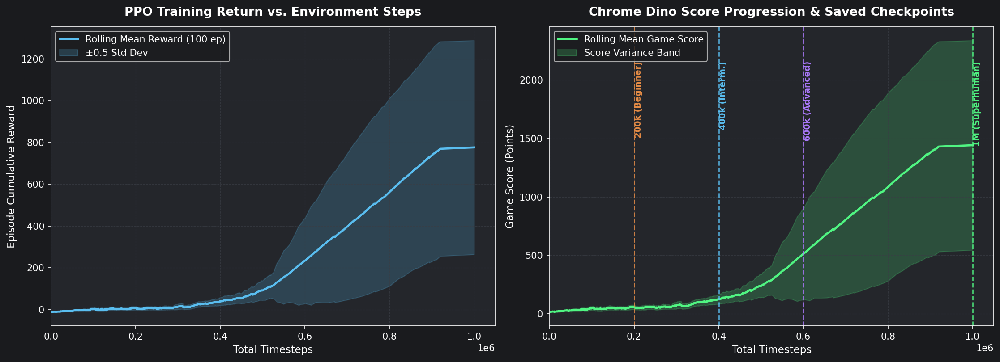

📊 Saved high-res chart to: dino_learning_curves.png


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [9]:
import glob
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. Load & merge episode logs from all 8 parallel environments
log_files = glob.glob("dino_logs/*.monitor.csv")
dfs = []
for f in log_files:
    # Skip the first comment line (#{"t_start": ...}) written by SB3 Monitor
    df = pd.read_csv(f, skiprows=1)
    dfs.append(df)

full_df = pd.concat(dfs, ignore_index=True)
# Sort chronologically by wall-clock time 't' and reconstruct cumulative environment timesteps
full_df = full_df.sort_values(by="t").reset_index(drop=True)
full_df["total_timesteps"] = full_df["l"].cumsum()
full_df["approx_score"] = full_df["l"] // 3  # Convert survival frames to Dino game score

# Extend the DataFrame explicitly to 1M steps so the rolling window doesn't prematurely drop off
# (Because running logs only record completed episodes, the final episodes often aren't logged before the 1M cutoff)
last_row = full_df.iloc[-1].copy()
last_row["total_timesteps"] = 1_000_000
full_df = pd.concat([full_df, pd.DataFrame([last_row])], ignore_index=True)

# 2. Compute Rolling Mean & Standard Deviation Bands (window = 100 episodes)
window = 100
full_df["reward_mean"] = full_df["r"].rolling(window, min_periods=10).mean()
full_df["reward_std"] = full_df["r"].rolling(window, min_periods=10).std().fillna(0)

full_df["score_mean"] = full_df["approx_score"].rolling(window, min_periods=10).mean()
full_df["score_std"] = full_df["approx_score"].rolling(window, min_periods=10).std().fillna(0)

# 3. Create Dark-Mode Portfolio Plot (Matching Chrome Dino Aesthetic)
plt.style.use("dark_background")
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5.5), dpi=150)
fig.patch.set_facecolor("#1a1b1e")

milestone_steps = [
    (200_000, "200k (Beginner)", "#e68c46"),
    (400_000, "400k (Interm.)", "#5abef0"),
    (600_000, "600k (Advanced)", "#aa78fa"),
    (1_000_000, "1M (Superhuman)", "#50f582"),
]

# --- PANEL 1: Episode Reward Curve ---
ax1.set_facecolor("#24262b")
ax1.plot(full_df["total_timesteps"], full_df["reward_mean"], color="#5abef0", linewidth=2.2, label="Rolling Mean Reward (100 ep)")
ax1.fill_between(
    full_df["total_timesteps"],
    full_df["reward_mean"] - 0.5 * full_df["reward_std"],
    full_df["reward_mean"] + 0.5 * full_df["reward_std"],
    color="#5abef0", alpha=0.2, label="±0.5 Std Dev"
)
ax1.set_title("PPO Training Return vs. Environment Steps", fontsize=13, fontweight="bold", pad=12)
ax1.set_xlabel("Total Timesteps", fontsize=11)
ax1.set_ylabel("Episode Cumulative Reward", fontsize=11)
ax1.grid(color="#3a3d45", linestyle="--", linewidth=0.6, alpha=0.7)
ax1.set_xlim(left=0, right=1_050_000)  # Force axis to show the full million steps

# --- PANEL 2: Game Score Progression & Checkpoint Milestones ---
ax2.set_facecolor("#24262b")
ax2.plot(full_df["total_timesteps"], full_df["score_mean"], color="#50f582", linewidth=2.2, label="Rolling Mean Game Score")
ax2.fill_between(
    full_df["total_timesteps"],
    np.maximum(0, full_df["score_mean"] - 0.5 * full_df["score_std"]),
    full_df["score_mean"] + 0.5 * full_df["score_std"],
    color="#50f582", alpha=0.2, label="Score Variance Band"
)

# Overlay vertical dashed lines for ALL saved checkpoints regardless of log cutoff
for step_val, lbl, col in milestone_steps:
    ax2.axvline(x=step_val, color=col, linestyle="--", linewidth=1.3, alpha=0.85)
    ax2.text(
        step_val, ax2.get_ylim()[1] * 0.88, f" {lbl}",
        color=col, rotation=90, verticalalignment="top", fontsize=9, fontweight="bold"
    )

ax2.set_title("Chrome Dino Score Progression & Saved Checkpoints", fontsize=13, fontweight="bold", pad=12)
ax2.set_xlabel("Total Timesteps", fontsize=11)
ax2.set_ylabel("Game Score (Points)", fontsize=11)
ax2.grid(color="#3a3d45", linestyle="--", linewidth=0.6, alpha=0.7)
ax2.set_xlim(left=0, right=1_050_000)  # Force axis to show the full million steps

ax1.legend(loc="upper left", frameon=True, facecolor="#1a1b1e")
ax2.legend(loc="upper left", frameon=True, facecolor="#1a1b1e")

plt.tight_layout()
plt.savefig("dino_learning_curves.png", dpi=300, bbox_inches="tight")
plt.show()
print("📊 Saved high-res chart to: dino_learning_curves.png")

In [10]:
!pip install imageio[pyav]

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.0/35.0 MB 43.3 MB/s  0:00:00


### Convert `.mp4` Videos to Optimized GitHub `.gif` Assets

In [11]:
import os
import imageio.v3 as iio
from PIL import Image

def mp4_to_github_gif(mp4_path, gif_path, fps=15, max_seconds=20, resize_width=650):
    """Converts an MP4 into an optimized, fast-loading GIF (<5MB) for GitHub READMEs."""
    if not os.path.exists(mp4_path):
        print(f"⚠️ {mp4_path} not found. Run the video generation cell first.")
        return

    frames = iio.imread(mp4_path, plugin="pyav")
    # Subsample from 30 FPS to 15 FPS and cap duration for fast web loading
    step = max(1, 30 // fps)
    max_frames = fps * max_seconds
    selected_frames = frames[::step][:max_frames]

    pil_frames = []
    for f in selected_frames:
        img = Image.fromarray(f)
        w, h = img.size
        new_h = int(h * (resize_width / w))
        img = img.resize((resize_width, new_h), Image.Resampling.LANCZOS)
        # Quantize to 64 colors (ideal for dark-mode pixel art & keeps file size tiny)
        img = img.quantize(colors=64, method=Image.Quantize.FASTOCTREE)
        pil_frames.append(img)

    pil_frames[0].save(
        gif_path,
        save_all=True,
        append_images=pil_frames[1:],
        optimize=True,
        duration=int(1000 / fps),
        loop=0
    )
    size_mb = os.path.getsize(gif_path) / (1024 * 1024)
    print(f"✅ Saved {gif_path} ({size_mb:.2f} MB) — Ready for GitHub README!")

# Convert both showcase videos into README-ready GIFs
mp4_to_github_gif("dino_50_ghost_battle_royale.mp4", "dino_ghost_royale.gif", fps=15, max_seconds=60)
mp4_to_github_gif("dino_learning_progression_reel.mp4", "dino_learning progress.gif", fps=15, max_seconds=60)

✅ Saved dino_ghost_royale.gif (10.79 MB) — Ready for GitHub README!
✅ Saved dino_learning progress.gif (5.68 MB) — Ready for GitHub README!


In [17]:
import shutil
from google.colab import files

# Zip the entire checkpoints directory
shutil.make_archive("dino_logs", "zip", "dino_logs")

# Download the zipped file
files.download("dino_logs.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>